## Preparing the data

This clustering analysis uses three storm-level characteristics: **peak wind speed (kt)** to represent cyclone intensity, **observed track duration (days)** to describe how long each cyclone was recorded, and **mean translation speed (kt)** to measure its average movement speed.

The processed IBTrACS file has one row per timestamp. We summarize each `SID` into one cyclone: maximum USA wind, first-to-last **observed** track span, and mean translation speed. The observed span is not necessarily the cyclone's physical lifetime. We keep basin and minimum pressure for interpretation, but neither enters the main clustering distance. Pressure and wind are highly correlated, so using both would overweight intensity.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth
from scipy.optimize import linear_sum_assignment

DATA_PATH = Path("datasets/processed/cyclones_2010_2025.csv")
df = pd.read_csv(DATA_PATH, parse_dates=["ISO_TIME"], keep_default_na=False, na_values=[""])

BASIN_ORDER = ["NA", "EP", "WP", "NI", "SI", "SP", "SA"]
sns.set_theme(style="whitegrid", context="talk", palette="colorblind", font_scale=.82)
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False, "grid.alpha": .22, "axes.titleweight": "bold"})

ordered = df.sort_values(["SID", "ISO_TIME"])
storm_df = ordered.groupby("SID", sort=False).agg(first=("ISO_TIME", "first"), last=("ISO_TIME", "last"), observations=("SID", "size"), max_wind=("USA_WIND", "max"), min_pressure=("USA_PRES", "min"), mean_speed=("STORM_SPEED", "mean"))
storm_df["duration_days"] = (storm_df["last"] - storm_df["first"]).dt.total_seconds() / 86400
basin_visits = ordered.groupby(["SID", "BASIN"]).size().rename("fixes").reset_index().sort_values(["SID", "fixes", "BASIN"], ascending=[True, False, True])
storm_df["basin"] = basin_visits.drop_duplicates("SID").set_index("SID")["BASIN"]

FEATURES = ["max_wind", "duration_days", "mean_speed"]
FEATURE_LABELS = ["Peak USA wind (kt)", "Observed track span (days)", "Mean translation speed (kt)"]
complete = storm_df.dropna(subset=FEATURES).copy()

print(f"Timestamped records: {len(df):,}; distinct cyclones: {len(storm_df):,}")
print(f"Complete storm-level samples: {len(complete):,}; excluded for missing selected features: {len(storm_df) - len(complete):,}")
print("Feature coverage:", storm_df[FEATURES].notna().sum().to_dict())
print(f"Peak wind versus minimum pressure on complete cases: r = {complete.max_wind.corr(complete.min_pressure):.3f}")
coverage = storm_df.assign(included=storm_df.index.isin(complete.index)).groupby("basin").included.agg(["sum", "count"]).reindex(BASIN_ORDER)
print("Included / total by representative basin:", {basin: f"{row['sum']:.0f}/{row['count']:.0f}" for basin, row in coverage.iterrows()})

Timestamped records: 100,949; distinct cyclones: 1,667
Complete storm-level samples: 1,538; excluded for missing selected features: 129
Feature coverage: {'max_wind': 1538, 'duration_days': 1667, 'mean_speed': 1667}
Peak wind versus minimum pressure on complete cases: r = -0.966
Included / total by representative basin: {'NA': '289/289', 'EP': '318/318', 'WP': '451/469', 'NI': '90/166', 'SI': '248/274', 'SP': '140/149', 'SA': '2/2'}


### Standardizing the three features

Wind and speed are measured in knots, while track span is measured in days; their raw numerical scales differ. `StandardScaler` subtracts the mean and divides by the standard deviation of each feature so distance-based algorithms compare them on a common scale.

In [2]:
scaler = StandardScaler()
X = scaler.fit_transform(complete[FEATURES])
assert X.shape == (len(complete), 3) and np.isfinite(X).all()
print("Scaled feature means:", np.round(X.mean(axis=0), 3))
print("Scaled feature standard deviations:", np.round(X.std(axis=0), 3))

Scaled feature means: [-0. -0.  0.]
Scaled feature standard deviations: [1. 1. 1.]


## PCA — visualizing the cyclones

Principal Component Analysis combines the three standardized characteristics into new directions. We use its first two directions only to **draw a two-dimensional map**; K-means and Mean-Shift still use all three original standardized features.

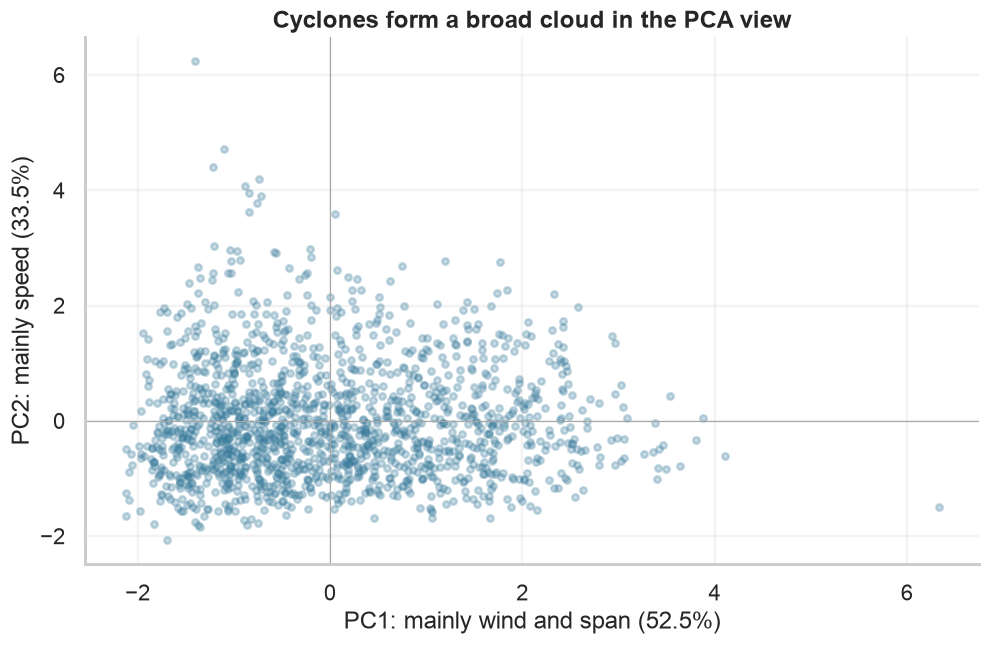

Variance shown by the two axes: 85.9%


In [3]:
pca = PCA(n_components=2)
coords = pca.fit_transform(X)
variance = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(8.5, 5.5), constrained_layout=True)
ax.scatter(coords[:, 0], coords[:, 1], s=17, alpha=.28, color="#397B9B", rasterized=True)
ax.axhline(0, color="0.65", linewidth=.7)
ax.axvline(0, color="0.65", linewidth=.7)
ax.set(title="Cyclones form a broad cloud in the PCA view", xlabel=f"PC1: mainly wind and span ({variance[0]:.1%})", ylabel=f"PC2: mainly speed ({variance[1]:.1%})")
plt.show()
print(f"Variance shown by the two axes: {variance.sum():.1%}")

The two axes show **85.9%** of the standardized variation. PC1 mainly combines wind and observed span; PC2 mainly reflects speed. The points form a broad cloud without obvious isolated islands. This picture helps us see the data, but it does not establish natural cluster boundaries.

## Choosing K

We compare **K = 2, 3, and 4**. For stability, each K-means model is refitted on twelve different random **80% subsamples**. Each refit assigns all 1,538 storms, and we compare its assignments with the full-data fit after matching the arbitrary cluster labels. A stable assignment is useful, but even stable K-means groups need not be natural categories. Agreement with Mean-Shift, basin composition, and profile interpretation are examined below.

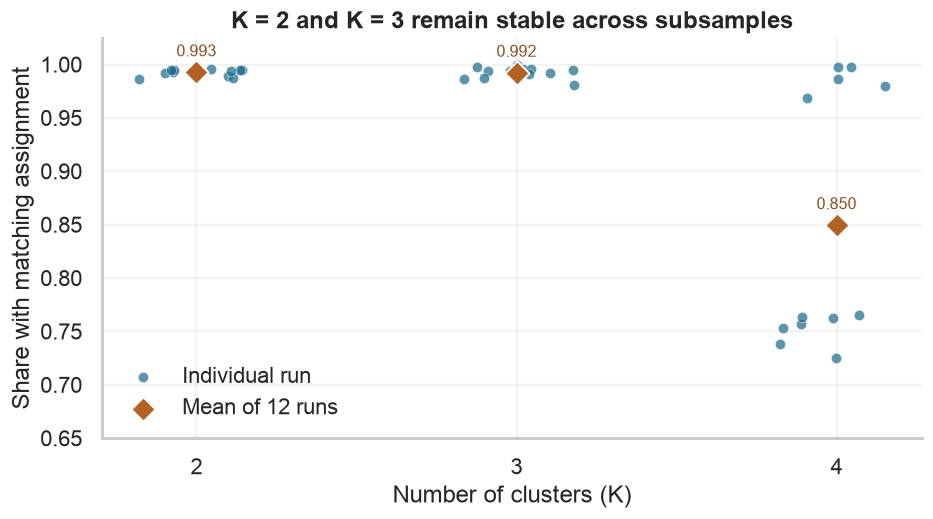

Mean assignment agreement: {2: 0.993, 3: 0.992, 4: 0.85}


In [4]:
candidate_k = [2, 3, 4]
candidate_models = {k: KMeans(n_clusters=k, random_state=42, n_init=20).fit(X) for k in candidate_k}
rng = np.random.default_rng(42)
subsets = [rng.choice(len(X), size=int(.8 * len(X)), replace=False) for _ in range(12)]
stability = {}
for k in candidate_k:
    reference = candidate_models[k].labels_
    shares = []
    for subset in subsets:
        predicted = KMeans(n_clusters=k, random_state=42, n_init=20).fit(X[subset]).predict(X)
        overlap = pd.crosstab(reference, predicted).reindex(index=range(k), columns=range(k), fill_value=0).to_numpy()
        rows, columns = linear_sum_assignment(-overlap)
        shares.append(overlap[rows, columns].sum() / len(X))
    stability[k] = shares

fig, ax = plt.subplots(figsize=(8, 4.4), constrained_layout=True)
jitter_rng = np.random.default_rng(7)
means = [np.mean(stability[k]) for k in candidate_k]
for x, k in enumerate(candidate_k):
    jitter = jitter_rng.uniform(-.18, .18, len(stability[k]))
    ax.scatter(x + jitter, stability[k], s=42, alpha=.7, color="#176A8A", edgecolor="white", linewidth=.4, label="Individual run" if x == 0 else None)
ax.scatter(range(len(candidate_k)), means, s=115, marker="D", color="#B36224", edgecolor="white", linewidth=1.2, zorder=4, label="Mean of 12 runs")
for x, mean in enumerate(means):
    ax.annotate(f"{mean:.3f}", (x, mean), xytext=(0, 10), textcoords="offset points", ha="center", color="#8B4A1C", fontsize=10)
ax.set(title="K = 2 and K = 3 remain stable across subsamples", xlabel="Number of clusters (K)", ylabel="Share with matching assignment", xticks=range(len(candidate_k)), xticklabels=candidate_k, ylim=(.65, 1.025))
ax.legend(frameon=False, loc="lower left")
plt.show()
print("Mean assignment agreement:", {k: float(round(np.mean(stability[k]), 3)) for k in candidate_k})

**Stability:** K = 2 and K = 3 have almost identical mean assignment agreement across these subsamples (**0.993** and **0.992**); K = 4 is lower and more variable (**0.850**). This argues against adding a fourth group. High agreement reflects a reproducible partition of these measurements, not proof of naturally separate cyclone types.

## K-means — interpreting a candidate grouping

K-means repeatedly assigns each cyclone to the nearest group center and updates the centers. **K = 3 remains a candidate** because it is as stable as K = 2 and may describe the movement dimension more clearly. The seed and 20 initializations are fixed for reproducibility.

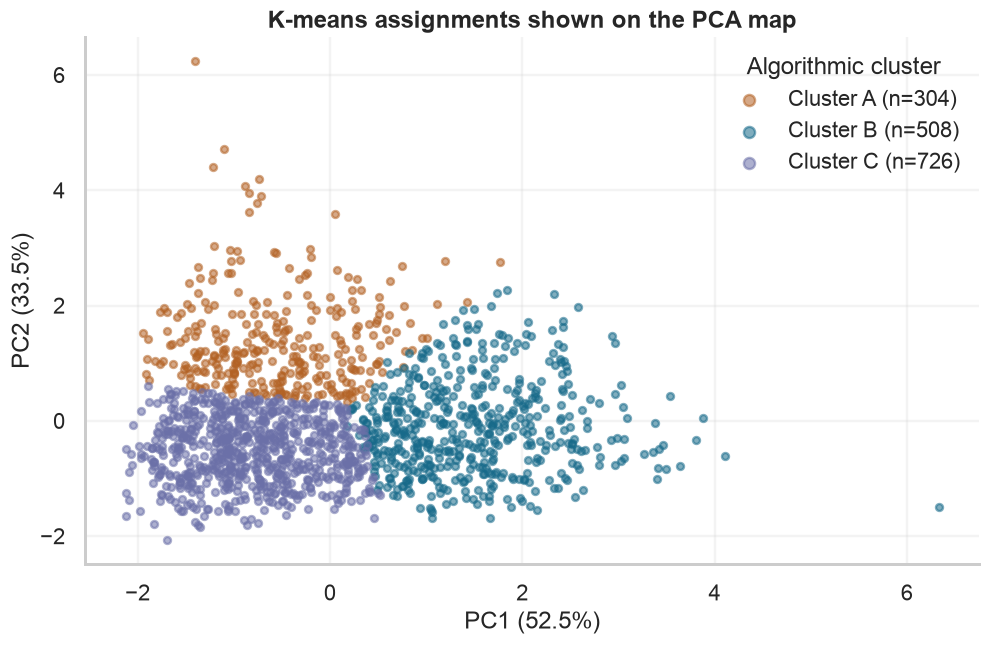

Cluster sizes: {'A': 304, 'B': 508, 'C': 726}


In [5]:
kmeans = candidate_models[3]
cluster_order = ["A", "B", "C"]
cluster_colors = {"A": "#B36224", "B": "#176A8A", "C": "#6B70A8"}
complete["cluster"] = pd.Categorical([cluster_order[i] for i in kmeans.labels_], categories=cluster_order)
fig, ax = plt.subplots(figsize=(8.5, 5.5), constrained_layout=True)
for label in cluster_order:
    mask = complete.cluster.eq(label).to_numpy()
    ax.scatter(coords[mask, 0], coords[mask, 1], s=19, alpha=.55, color=cluster_colors[label], label=f"Cluster {label} (n={mask.sum():,})", rasterized=True)
ax.set(title="K-means assignments shown on the PCA map", xlabel=f"PC1 ({variance[0]:.1%})", ylabel=f"PC2 ({variance[1]:.1%})")
ax.legend(frameon=False, markerscale=1.6, title="Algorithmic cluster")
plt.show()
print("Cluster sizes:", complete.cluster.value_counts().sort_index().to_dict())

The K-means groups contain **304 storms in A**, **508 in B**, and **726 in C**. A appears toward faster movement, B toward stronger wind and longer observed spans, and C toward lower wind, shorter spans, and slower movement.

## The clusters

The three box plots are the main explanation of the K-means result. They show the distribution of **wind, observed span, and speed** in each group. These are the same features used to create the groups, so their differences describe the assignments rather than independently validate them.

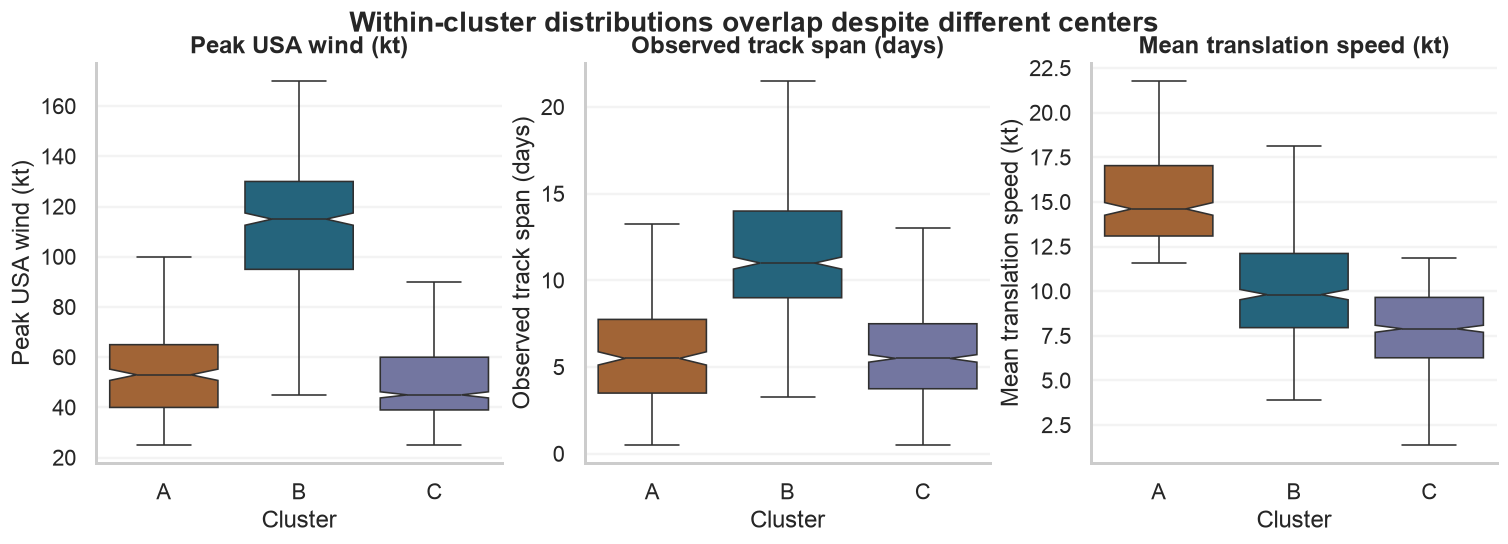

Feature medians by cluster:
         max_wind  duration_days  mean_speed  min_pressure
cluster                                                   
A            53.0            5.5        14.6         989.0
B           115.0           11.0         9.8         942.0
C            45.0            5.5         7.9         993.0


In [6]:
plot_data = complete.reset_index()
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), constrained_layout=True)
for ax, feature, label in zip(axes, FEATURES, FEATURE_LABELS):
    sns.boxplot(data=plot_data, notch=True, x="cluster", y=feature, hue="cluster", order=cluster_order, hue_order=cluster_order, palette=cluster_colors, dodge=False, legend=False, showfliers=False, ax=ax)
    ax.set(xlabel="Cluster", ylabel=label, title=label)
fig.suptitle("Within-cluster distributions overlap despite different centers", y=1.04, fontweight="bold")
plt.show()
print("Feature medians by cluster:")
print(complete.groupby("cluster", observed=True)[FEATURES + ["min_pressure"]].median().round(1).to_string())

The medians are **A: 53 kt, 5.5 days, 14.6 kt**; **B: 115 kt, 11.0 days, 9.8 kt**; and **C: 45 kt, 5.5 days, 7.9 kt** (wind, span, speed). Thus A is relatively fast-moving, B stronger and longer-observed, and C lower-wind and slower. The boxes overlap, especially A and C for wind and span. Minimum pressure, which was not clustered, is lowest in B (**942 hPa**), but it is strongly related to wind and is only a consistency check.

## K-means Clusters with a Decision Tree

A shallow decision tree turns the existing K-means labels into a few readable rules. It uses the **same three storm-level features in their original units**: peak wind, observed span, and mean speed. We limit it to three levels and at least 30 training storms per leaf. A stratified 75%/25% split checks how well the tree reproduces K-means assignments for storms it did not train on.

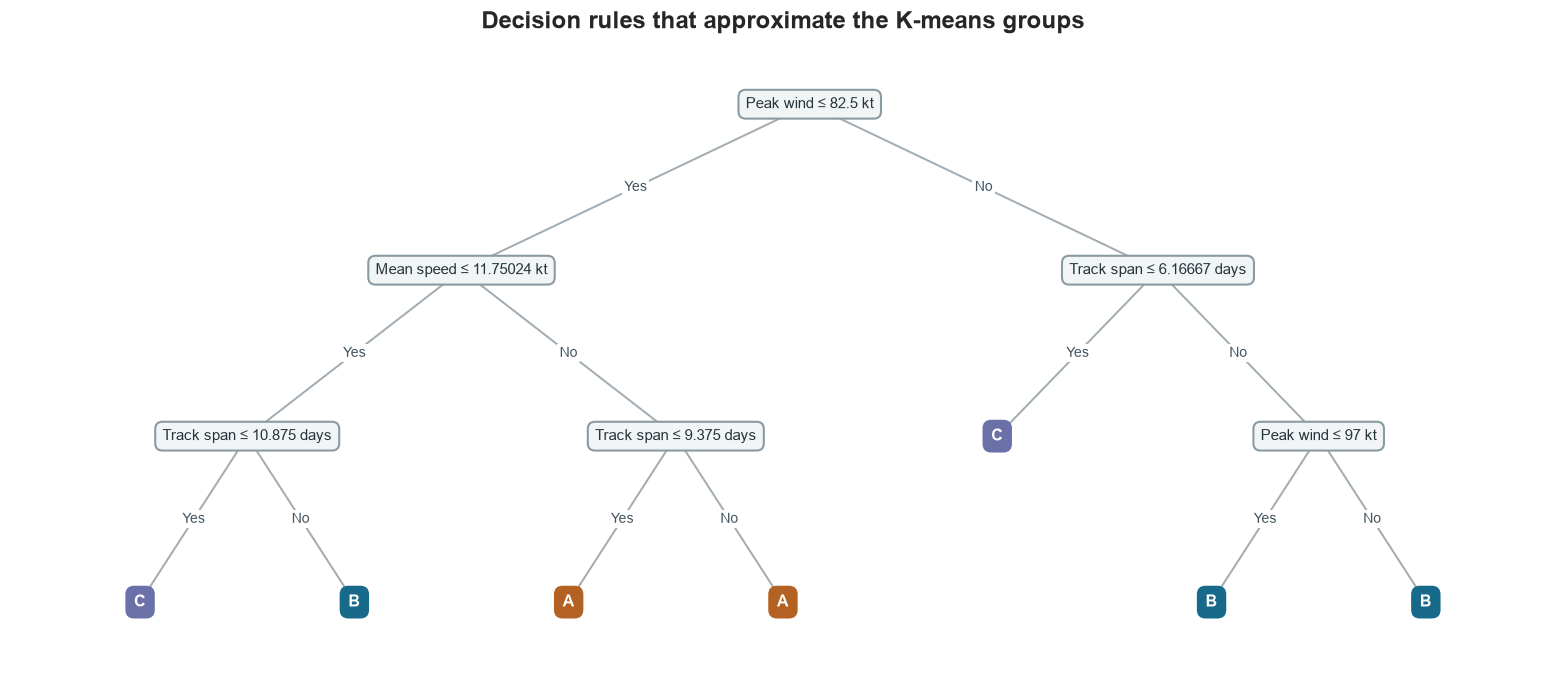

Held-out agreement: 90.1% (347/385 storms)
Tree      A    B    C
K-means              
A        64    5    7
B         3  113   11
C         1   11  170


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

X_tree = complete[FEATURES]
y_tree = complete["cluster"].astype(str)
X_train, X_test, y_train, y_test = train_test_split(X_tree, y_tree, test_size=.25, stratify=y_tree, random_state=42)
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=30, random_state=42)
tree.fit(X_train, y_train)
y_pred = tree.predict(X_test)

nodes = tree.tree_
positions = {}
leaf_number = [0]

def place_node(node, depth):
    left = nodes.children_left[node]
    if left == -1:
        x = leaf_number[0]
        leaf_number[0] += 1
    else:
        left_x = place_node(left, depth + 1)
        right_x = place_node(nodes.children_right[node], depth + 1)
        x = (left_x + right_x) / 2
    positions[node] = (x, 3 - depth)
    return x

place_node(0, 0)
short_features = [("Peak wind", "kt"), ("Track span", "days"), ("Mean speed", "kt")]
fig, ax = plt.subplots(figsize=(13.5, 5.8), constrained_layout=True)
for node in range(nodes.node_count):
    left = nodes.children_left[node]
    if left != -1:
        x, y = positions[node]
        for child, branch in [(left, "Yes"), (nodes.children_right[node], "No")]:
            child_x, child_y = positions[child]
            ax.plot([x, child_x], [y, child_y], color="#A2ADB3", linewidth=1.25, zorder=1)
            ax.text((x + child_x) / 2, (y + child_y) / 2, branch, ha="center", va="center", fontsize=9, color="#41545F", bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5}, zorder=2)

for node in range(nodes.node_count):
    x, y = positions[node]
    is_leaf = nodes.children_left[node] == -1
    if is_leaf:
        label = tree.classes_[nodes.value[node][0].argmax()]
        face_color = cluster_colors[label]
        edge_color = face_color
        text_color = "white"
    else:
        feature, unit = short_features[nodes.feature[node]]
        threshold = f"{nodes.threshold[node]:.5f}".rstrip("0").rstrip(".")
        label = f"{feature} ≤ {threshold} {unit}"
        face_color = "#F2F5F6"
        edge_color = "#8A9AA3"
        text_color = "#26343B"
    ax.text(x, y, label, ha="center", va="center", fontsize=10 if is_leaf else 9.5, fontweight="bold" if is_leaf else "normal", color=text_color, bbox={"boxstyle": "round,pad=.48", "facecolor": face_color, "edgecolor": edge_color, "linewidth": 1.3}, zorder=3)

ax.set(xlim=(-.6, leaf_number[0] - .4), ylim=(-.4, 3.4), title="Decision rules that approximate the K-means groups")
ax.axis("off")
plt.show()
print(f"Held-out agreement: {accuracy_score(y_test, y_pred):.1%} ({(y_test == y_pred).sum()}/{len(y_test)} storms)")
print(pd.crosstab(y_test.rename("K-means"), pd.Series(y_pred, index=y_test.index, name="Tree")).reindex(index=cluster_order, columns=cluster_order, fill_value=0).to_string())

The first split is at **82.5 kt peak wind**. Among lower-wind storms, mean speed above about **11.8 kt** usually leads to A; slower, shorter tracks usually lead to C. Higher-wind storms with more than about **6.2 observed days** usually lead to B. The tree matches **347 of 385 held-out K-means labels (90.1%)**; the remaining cases lie across simplified rule boundaries. These labels were produced by K-means from the same three features, so the tree **explains that partition but does not validate the existence of natural clusters**.

## Mean-Shift 

Mean-Shift looks for dense regions without asking us to choose K directly. Its bandwidth sets the neighborhood size; changing it can merge or split groups. We estimate one bandwidth from sampled distances in the same standardized three-feature space and compare the resulting picture with K-means.

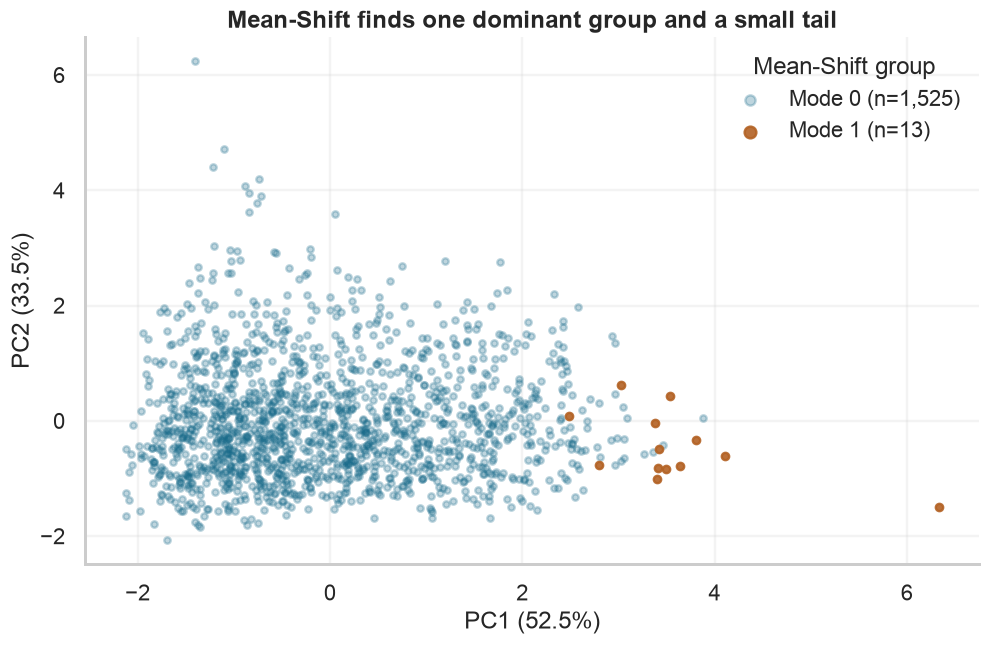

Bandwidth: 1.56; group sizes: {0: 1525, 1: 13}
            max_wind  duration_days
mean_shift                         
0               60.0            7.2
1              130.0           22.2
K-means groups within each Mean-Shift group:
mean_shift    0   1
cluster            
A           304   0
B           495  13
C           726   0


In [8]:
bandwidth = estimate_bandwidth(X, quantile=.25, n_samples=500, random_state=42)
meanshift = MeanShift(bandwidth=bandwidth, bin_seeding=True).fit(X)
complete["mean_shift"] = meanshift.labels_
ms_sizes = complete.mean_shift.value_counts().sort_index()
ms_palette = {label: ("#176A8A" if size == ms_sizes.max() else "#B36224") for label, size in ms_sizes.items()}
fig, ax = plt.subplots(figsize=(8.5, 5.5), constrained_layout=True)
for label, size in ms_sizes.items():
    mask = complete.mean_shift.eq(label).to_numpy()
    ax.scatter(coords[mask, 0], coords[mask, 1], s=21 if size < 100 else 16, alpha=.9 if size < 100 else .28, color=ms_palette[label], label=f"Mode {label} (n={size:,})", rasterized=True, zorder=3 if size < 100 else 2)
ax.set(title="Mean-Shift finds one dominant group and a small tail", xlabel=f"PC1 ({variance[0]:.1%})", ylabel=f"PC2 ({variance[1]:.1%})")
ax.legend(frameon=False, markerscale=1.6, title="Mean-Shift group")
plt.show()
print(f"Bandwidth: {bandwidth:.2f}; group sizes: {ms_sizes.to_dict()}")
print(complete.groupby("mean_shift")[["max_wind", "duration_days"]].median().round(1).to_string())
print("K-means groups within each Mean-Shift group:")
print(pd.crosstab(complete.cluster, complete.mean_shift).to_string())

With bandwidth **1.56**, Mean-Shift identifies two groups:

- **Main group (1,525 storms):** Contains nearly all cyclones, including a wide range of intensities, durations, and movement speeds.
- **Small group (13 storms):** Contains particularly intense and long-observed cyclones, with a median peak wind of **130 kt** and an observed duration of **22.2 days**.

Unlike K-means, Mean-Shift does not identify three distinct profiles. Instead, it finds one dominant group and a small subset of extreme cyclones, all belonging to K-means cluster B.

This disagreement suggests that the three K-means profiles are descriptive partitions rather than clearly separated natural categories. The Mean-Shift results also depend on the selected bandwidth.

## Conclusion

**Can tropical cyclones be grouped into meaningful profiles based on their intensity, duration and movement characteristics?**

**The results do not provide strong evidence of clearly separated natural cyclone groups.** Although K-means identifies three interpretable profiles, their distributions overlap considerably. The stability analysis shows that K = 2 and K = 3 produce highly consistent assignments across subsamples, while K = 4 is less stable. However, Mean-Shift produces a substantially different grouping, suggesting that the three-cluster structure is not consistently supported across methods.

These findings suggest that cyclone characteristics may vary more continuously rather than forming distinct natural categories. Therefore, the K-means clusters are best understood as descriptive groupings, not established meteorological types.